<a href="https://colab.research.google.com/github/shub1504/ML_project/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from pathlib import Path

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [ ]:

# Cell 2: Upload the downloaded UCI CSV file

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError(
        "No CSV file found. Please upload the extracted dataset CSV."
    )

DATA_PATH = Path(csv_files[0])

print("Dataset file:", DATA_PATH.name)


Saving maternal_health_risk.csv to maternal_health_risk.csv
Dataset file: maternal_health_risk.csv


In [ ]:

# Cell 3: Load the dataset

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
Number of records: 1014
Number of columns: 7

First five records:


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk



Column names:
['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


In [ ]:

# Cell 4: Basic data-quality assessment

print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nTarget class distribution:")
display(
    df["RiskLevel"]
    .value_counts()
    .rename_axis("Risk Level")
    .to_frame("Number of Records")
)

print("\nSummary statistics:")
display(df.describe(include="all").T)


Missing values per column:


,Missing Values
Age,0
SystolicBP,0
DiastolicBP,0
BS,0
BodyTemp,0
HeartRate,0
RiskLevel,0



Exact duplicate rows: 562

Target class distribution:


,Number of Records
Risk Level,
low risk,406
mid risk,336
high risk,272



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1014.0,NaN,NaN,NaN,29.871795,13.474386,10.0,19.0,26.0,39.0,70.0
SystolicBP,1014.0,NaN,NaN,NaN,113.198225,18.403913,70.0,100.0,120.0,120.0,160.0
DiastolicBP,1014.0,NaN,NaN,NaN,76.460552,13.885796,49.0,65.0,80.0,90.0,100.0
BS,1014.0,NaN,NaN,NaN,8.725986,3.293532,6.0,6.9,7.5,8.0,19.0
BodyTemp,1014.0,NaN,NaN,NaN,98.665089,1.371384,98.0,98.0,98.0,98.0,103.0
HeartRate,1014.0,NaN,NaN,NaN,74.301775,8.088702,7.0,70.0,76.0,80.0,90.0
RiskLevel,1014,3,low risk,406,NaN,NaN,NaN,NaN,NaN,NaN,NaN


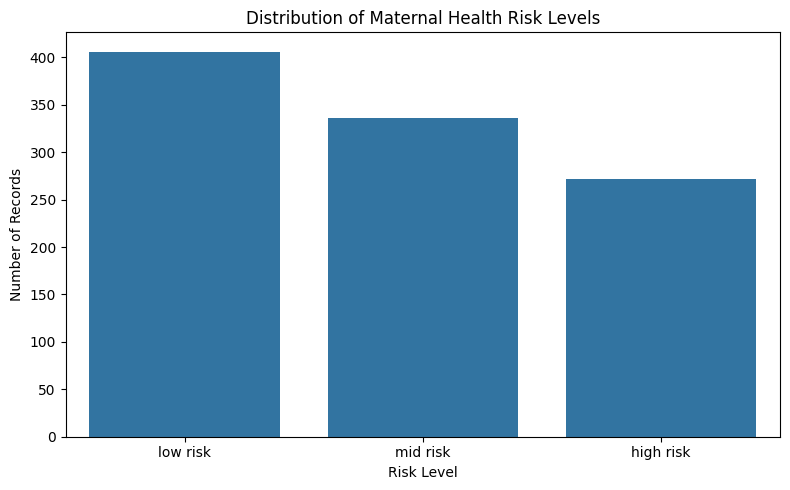

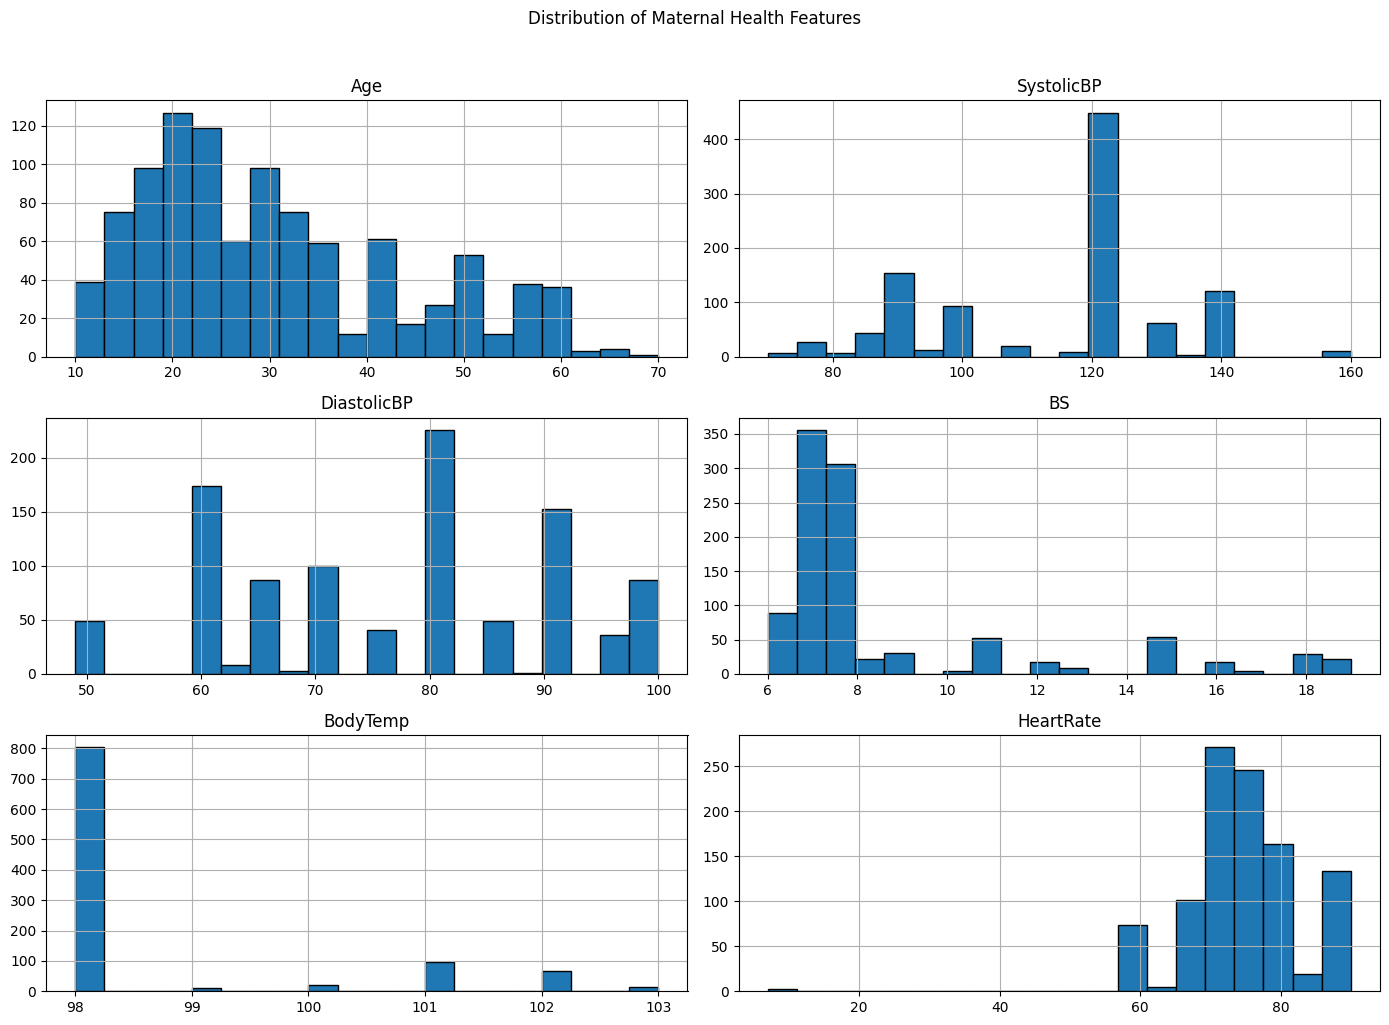

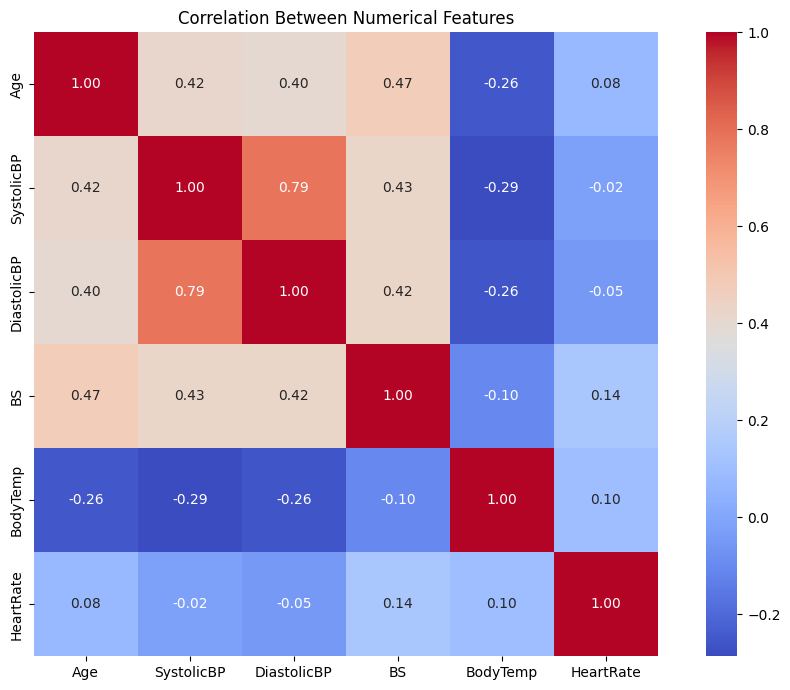

In [ ]:

# Cell 5: Exploratory Data Analysis (EDA)

# 1. Distribution of maternal risk levels
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="RiskLevel",
    order=df["RiskLevel"].value_counts().index
)
plt.title("Distribution of Maternal Health Risk Levels")
plt.xlabel("Risk Level")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


# 2. Distribution of numerical features
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

df[numeric_cols].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distribution of Maternal Health Features", y=1.02)
plt.tight_layout()
plt.show()


# 3. Correlation between numerical features
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()
